In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor  # for regression
import os
import matplotlib.pyplot as plt

from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_squared_error
import matplotlib.dates as mdates

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox


from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.tsa.ar_model import AutoReg

In [2]:
df = pd.read_csv("offshore_windspeeds_NVE_areas.csv")

In [3]:
df_Nordavind = df[(df["locID"] == 1) | (df["locID"] == 2) | (df["locID"] == 3) | (df["locID"] == 4)].copy()

In [4]:
def remove_leap_day(df):

    df = df.copy()

    #df["datetime"] = pd.to_datetime(df["datetime"])

    df = df.loc[
        ~(
            (df["datetime"].dt.month == 2) &
            (df["datetime"].dt.day == 29)
        )
    ].reset_index(drop=True)

    return df

start_datetime = pd.Timestamp('1996-01-01 00:00:00')
start_time_value = df_Nordavind['time'].min()
df_Nordavind['datetime'] = start_datetime + pd.to_timedelta(df_Nordavind['time'] - start_time_value, unit='h')



# Lager kolonner for dato, måned og dag ---
df_Nordavind["date"] = df_Nordavind["datetime"].dt.date
df_Nordavind["month"] = df_Nordavind["datetime"].dt.month
df_Nordavind["day"] = df_Nordavind["datetime"].dt.day

df_Nordavind = remove_leap_day(df_Nordavind)

In [5]:
# Sørger for at datetime er riktig format
df_Nordavind["datetime"] = pd.to_datetime(
    df_Nordavind["datetime"]
).dt.round("h")

# Sorter etter lokasjon og tid
df_Nordavind = df_Nordavind.sort_values(
    ["locID", "datetime"]
)

# Funksjon for å beregne gjennomsnitt
def aggregate_wind(df, freq):
    return (
        df.set_index("datetime")
        .groupby("locID")
        .resample(freq)["value"]
        .mean()
        .reset_index()
    )

# Ulike tidsoppløsninger
df_Nordavind_3h = aggregate_wind(df_Nordavind, "3h")
df_Nordavind_6h = aggregate_wind(df_Nordavind, "6h")
df_Nordavind_12h = aggregate_wind(df_Nordavind, "12h")
df_Nordavind_daily = aggregate_wind(df_Nordavind, "1D")

In [6]:
def pivot_wind(df):
    df_pivot = df.pivot(
        index="datetime",
        columns="locID",
        values="value"
    )

    df_pivot = df_pivot.rename(columns={
        1: "Nordavind_A",
        2: "Nordavind_B",
        3: "Nordavind_C",
        4: "Nordavind_D"
    })

    return df_pivot.reset_index()

In [7]:
df_Nordavind_3h = pivot_wind(df_Nordavind_3h)

df_Nordavind_6h = pivot_wind(df_Nordavind_6h)

df_Nordavind_12h= pivot_wind(df_Nordavind_12h)

df_Nordavind_daily = pivot_wind(df_Nordavind_daily)

In [8]:
df_Nordavind_3h = remove_leap_day(df_Nordavind_3h)
df_Nordavind_6h = remove_leap_day(df_Nordavind_6h)
df_Nordavind_12h = remove_leap_day(df_Nordavind_12h)
df_Nordavind_daily = remove_leap_day(df_Nordavind_daily)

In [9]:
for name, df in [
    ("3 timer", df_Nordavind_3h),
    ("6 timer", df_Nordavind_6h),
    ("12 timer", df_Nordavind_12h),
    ("Daglig", df_Nordavind_daily)
]:
    print(name, len(df), df.isna().sum().sum())

3 timer 70080 0
6 timer 35040 0
12 timer 17520 0
Daglig 8760 0


In [10]:


torch.manual_seed(42)
np.random.seed(42)

locations = [
    "Nordavind_A",
    "Nordavind_B",
    "Nordavind_C",
    "Nordavind_D"
]

# Bruke "Nordavind_A" som målvariabel
target_location = "Nordavind_A"

datasets = {
    "3 timer": (df_Nordavind_3h, 56, 8),
    "6 timer": (df_Nordavind_6h, 28, 4),
    "12 timer": (df_Nordavind_12h, 14, 2),
    "Daglig": (df_Nordavind_daily, 7, 1),
    "Daglig sesongjustert": (df_Nordavind_daily, 7, 1)
}

rf_params = dict(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)


In [11]:
def normalize_data(df):
    df = df.copy()

    if "datetime" not in df.columns:
        df = df.reset_index()

    df["datetime"] = pd.to_datetime(df["datetime"])

    df = df[["datetime"] + locations]
    df = df.sort_values("datetime")
    df = df.drop_duplicates(subset="datetime")

    # Fjern 29. februar
    leap = (
        (df["datetime"].dt.month == 2) &
        (df["datetime"].dt.day == 29)
    )
    df = df.loc[~leap].copy()

    df[locations] = df[locations].apply(
        pd.to_numeric, errors="coerce"
    )
    df[locations] = df[locations].replace(
        [np.inf, -np.inf], np.nan
    )

    if df[locations].isna().any().any():
        raise ValueError("Fortsatt NaN i vindobservasjonene.")

    return df.set_index("datetime").sort_index()


def season_features(index):
    index = pd.DatetimeIndex(index)

    day = index.dayofyear.to_numpy().astype(float)

    # Juster dagnummer etter 29. februar i skuddår
    after_feb = index.month > 2
    day -= (index.is_leap_year & after_feb).astype(int)

    # Ta også hensyn til klokkeslett
    fraction = (
        index.hour.to_numpy() / 24 +
        index.minute.to_numpy() / 1440
    )

    t = day - 1 + fraction

    return np.column_stack([
        np.ones(len(index)),
        np.cos(2 * np.pi * t / 365),
        np.sin(2 * np.pi * t / 365)
    ])


def fit_season(train_df, full_index):
    X_train = season_features(train_df.index)
    X_full = season_features(full_index)

    seasonal = pd.DataFrame(
        index=full_index,
        columns=locations,
        dtype=float
    )

    coefficients = {}

    for loc in locations:
        beta = np.linalg.lstsq(
            X_train,
            train_df[loc].to_numpy(),
            rcond=None
        )[0]

        seasonal[loc] = X_full @ beta
        coefficients[loc] = beta

    return seasonal, coefficients


def prepare_data(df, p, h, seasonal=False):
    original = normalize_data(df)

    # Split basert på kronologiske observasjoner training 80% og test 20%
    split_raw = int(len(original) * 0.8)
    train_end = original.index[split_raw]

    if seasonal:
        season, coefficients = fit_season(
            original.iloc[:split_raw],
            original.index
        )
        working = original - season
    else:
        season = pd.DataFrame(
            0.0, index=original.index, columns=locations
        )
        coefficients = {}
        working = original.copy()

    lag_data = {}

    for lag in range(p):
        for loc in locations:
            lag_data[f"lag_{lag}_{loc}"] = (
                working[loc].shift(lag)
            )

    data = pd.DataFrame(lag_data, index=working.index)

    # Lager målvariabelen og dens tidsstempel, 24 timer frem i tid
    
    data["target"] = working[target_location].shift(-h)
    
    data["target_datetime"] = pd.Series(
        working.index, index=working.index
    ).shift(-h)

    lag_cols = [
        f"lag_{lag}_{loc}"
        for lag in range(p)
        for loc in locations
    ]

    # Kontroller faktiske tidsavstander
    step = pd.Timedelta(hours=24 / h)

    target_ok = (
        data["target_datetime"] - data.index == 
        pd.Timedelta(hours=24)
    )
    # Kontroller at alle lagene har kontinuerlig historikk
    history_ok = pd.Series(True, index=working.index)

    for lag in range(1, p):
        history_ok &= (
            working.index.to_series() -
            working.index.to_series().shift(lag)
            == lag * step
        )

    data = data.loc[target_ok & history_ok].dropna(
        subset=lag_cols + ["target", "target_datetime"]
    )
    # Lag en kolonne for sesongjustert målvariabel
    data["target_season"] = season[target_location].reindex(
        pd.to_datetime(data["target_datetime"])
    ).to_numpy()

    data["actual"] = (
        data["target"] + data["target_season"]
    )
    # Split trenings- og testsett tain 80% og 20% test
    train = data.loc[data.index < train_end].copy()
    test = data.loc[data.index >= train_end].copy()

    return {
        "original": original,
        "working": working,
        "season": season,
        "coefficients": coefficients,
        "data": data,
        "train": train,
        "test": test,
        "lag_cols": lag_cols,
        "train_end": train_end
    }

In [12]:
def train_rf(prepared):

    train = prepared["train"]
    test = prepared["test"]
    lag_cols = prepared["lag_cols"]

    model = RandomForestRegressor(**rf_params)

    model.fit(
        train[lag_cols],
        train["target"]
    )

    pred = model.predict(test[lag_cols])

    # Legg sesongkomponenten tilbake
    pred = pred + test["target_season"].to_numpy()

    return model, pred

In [13]:
def train_ar(prepared, p, h):

    working = prepared["working"]
    test = prepared["test"]
    train_end = prepared["train_end"]

    train_series = working.loc[
        working.index < train_end, locations
    ].copy()

    # Numerisk indeks for AutoReg
    train_series = train_series.reset_index(drop=True)

    # AR-modeller for B, C og D
    other_models = {}
    other_params = {}

    for loc in locations[1:]:
        result = AutoReg(
            train_series[loc],
            lags=p,
            trend="c",
            old_names=False
        ).fit()

        other_models[loc] = result
        other_params[loc] = np.asarray(result.params)

    # Eksterne lagvariabler for A
    # Lag alle eksterne lagvariabler samtidig
    exog_dict = {
        f"lag_{lag}_{loc}": train_series[loc].shift(lag)
        for lag in range(1, p + 1)
        for loc in locations[1:]
    }

    exog = pd.DataFrame(exog_dict)

    exog_cols = list(exog_dict.keys())

    # AutoReg ignorerer de første p radene ved estimering
    exog = exog.fillna(0.0)

    ar_a = AutoReg(
        train_series[target_location],
        lags=p,
        exog=exog[exog_cols],
        trend="c",
        old_names=False
    )

    ar_a_result = ar_a.fit()

    params_a = np.asarray(ar_a_result.params)

    c_a = params_a[0]
    phi_a = params_a[1:p + 1]
    beta_a = params_a[p + 1:]

    predictions = []

    for origin in test.index:

        history_df = working.loc[
            working.index <= origin, locations
        ].iloc[-p:]

        history = {
            loc: list(history_df[loc].to_numpy())
            for loc in locations
        }

        # Rekursiv prognose h steg
        for step in range(h):

            next_values = {}

            # Prognoser for B, C og D
            for loc in locations[1:]:
                params = other_params[loc]

                c = params[0]
                phi = params[1:]

                lag_values = np.array(
                    history[loc][-p:][::-1]
                )

                next_values[loc] = (
                    c + np.dot(phi, lag_values)
                )

            # Autoregressive lag for A
            lag_a = np.array(
                history[target_location][-p:][::-1]
            )

            # Eksterne lag fra B, C og D
            exog_values = np.array([
                history[loc][-lag]
                for lag in range(1, p + 1)
                for loc in locations[1:]
            ])

            next_values[target_location] = (
                c_a
                + np.dot(phi_a, lag_a)
                + np.dot(beta_a, exog_values)
            )

            # Oppdater alle fire seriene samtidig
            for loc in locations:
                history[loc].append(next_values[loc])

        predictions.append(
            history[target_location][-1]
        )

    predictions = np.asarray(predictions)

    # Legg sesongkomponenten tilbake
    predictions += test["target_season"].to_numpy()

    models = {
        "Nordavind_A_ARX": ar_a_result,
        "andre_lokasjoner": other_models
    }

    return models, predictions

In [14]:
class WindANN(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


def train_ann(prepared, epochs=100, patience=10):

    train = prepared["train"]
    test = prepared["test"]
    lag_cols = prepared["lag_cols"]

    # Kronologisk valideringssplit
    split_val = int(len(train) * 0.9)

    train_fit = train.iloc[:split_val]
    validation = train.iloc[split_val:]
   
    X_train = train_fit[lag_cols].to_numpy()
    y_train = train_fit["target"].to_numpy().reshape(-1, 1)

    X_val = validation[lag_cols].to_numpy()
    y_val = validation["target"].to_numpy().reshape(-1, 1)

    X_test = test[lag_cols].to_numpy()

    scaler_X = MinMaxScaler()
    scaler_y = MinMaxScaler()

    X_train = scaler_X.fit_transform(X_train)
    X_val = scaler_X.transform(X_val)
    X_test = scaler_X.transform(X_test)

    y_train = scaler_y.fit_transform(y_train)
    y_val = scaler_y.transform(y_val)

    X_train = torch.tensor(X_train, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.float32)

    X_val = torch.tensor(X_val, dtype=torch.float32)
    y_val = torch.tensor(y_val, dtype=torch.float32)

    X_test = torch.tensor(X_test, dtype=torch.float32)

    loader = DataLoader(
        TensorDataset(X_train, y_train),
        batch_size=32,
        shuffle=True
    )

    model = WindANN(len(lag_cols))

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    best_loss = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        model.train()
        batch_losses = []

        for xb, yb in loader:
            optimizer.zero_grad()

            prediction = model(xb)
            loss = criterion(prediction, yb)

            loss.backward()
            optimizer.step()

            batch_losses.append(loss.item())

        model.eval()

        with torch.no_grad():
            val_pred = model(X_val)
            val_loss = criterion(val_pred, y_val).item()

        train_loss = np.mean(batch_losses)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch + 1
            best_state = {
                k: v.detach().clone()
                for k, v in model.state_dict().items()
            }
            wait = 0
        else:
            wait += 1

        if wait >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        pred_scaled = model(X_test).numpy()

    pred = scaler_y.inverse_transform(
        pred_scaled
    ).ravel()

    # Legg sesongkomponenten tilbake
    pred += test["target_season"].to_numpy()

    training_info = {
        "train_loss": train_losses,
        "val_loss": val_losses,
        "best_epoch": best_epoch,
        "best_val_loss": best_loss,
        "scaler_X": scaler_X,
        "scaler_y": scaler_y
    }

    return model, pred, training_info

In [15]:

def train_benchmark(prepared):

    test = prepared["test"]

    # Historiske observasjoner fra Nordavind A
    lag_cols_a = [
        col for col in prepared["lag_cols"]
        if col.endswith("_Nordavind_A")
    ]

    # Persistens: siste kjente observasjon
    pred_persistence = (
        test["lag_0_Nordavind_A"].to_numpy()
    )

    # Historisk gjennomsnitt: siste 7 døgn
    pred_mean = (
        test[lag_cols_a].mean(axis=1).to_numpy()
    )

    # Sesongjustering
    season = prepared["season"]

    if prepared["coefficients"]:

        # Sesongkomponent på prognosetidspunktet
        target_season = test["target_season"].to_numpy()

        # Sesongkomponent på observasjonstidspunktet
        current_season = season.loc[
            test.index, target_location
        ].to_numpy()

        # Persistens i residualene + sesongprognose
        pred_persistence = (
            pred_persistence + target_season
        )

        # Gjennomsnitt av residualer + sesongprognose
        pred_mean = pred_mean + target_season

    return {
        "Persistens": pred_persistence,
        "Historisk gjennomsnitt": pred_mean
    }


In [16]:

results = []
predictions_all = {}
trained_models = {}
ann_training = {}
seasonal_coefficients = {}

for resolution, (df, p, h) in datasets.items():

    print(f"\n{'=' * 60}")
    print(f"Tidsoppløsning: {resolution}")
    print(f"Lag: {p} | Horisont: {h} steg")
    print("=" * 60)

    is_seasonal = resolution == "Daglig sesongjustert"

    prepared = prepare_data(
        df, p, h, seasonal=is_seasonal
    )

    test = prepared["test"]
    actual = test["actual"].to_numpy()

    dates = pd.DatetimeIndex(
        test["target_datetime"]
    )

    print("Trening:", len(prepared["train"]))
    print("Test:", len(test))
    print("Inngangsvariabler:", len(prepared["lag_cols"]))

    # Random Forest
    print("Trener Random Forest...")
    rf_model, pred_rf = train_rf(prepared)

    # AutoReg
    print("Trener AutoReg...")
    ar_model, pred_ar = train_ar(prepared, p, h)

    # ANN
    print("Trener ANN...")
    ann_model, pred_ann, ann_info = train_ann(prepared)
    
    print("Beregner benchmark...")
    benchmark_preds = train_benchmark(prepared)

    predictions_all[resolution] = pd.DataFrame({
    "datetime": dates,
    "Observert": actual,
    "Random Forest": pred_rf,
    "AutoReg": pred_ar,
    "ANN": pred_ann,
    "Persistens": benchmark_preds["Persistens"],
    "Historisk gjennomsnitt": benchmark_preds["Historisk gjennomsnitt"]
    })

    trained_models[resolution] = {
        "RF": rf_model,
        "AR": ar_model,
        "ANN": ann_model
    }

    ann_training[resolution] = ann_info

    seasonal_coefficients[resolution] = (
        prepared["coefficients"]
    )

    for name, pred in [
        ("Random Forest", pred_rf),
        ("AutoReg", pred_ar),
        ("ANN", pred_ann),
        ("Persistens", benchmark_preds["Persistens"]),
        ("Historisk gjennomsnitt", benchmark_preds["Historisk gjennomsnitt"])
    ]:

        mse = mean_squared_error(actual, pred)

        results.append({
            "Modell": name,
            "Tidsoppløsning": resolution,
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(actual, pred),
            "R²": r2_score(actual, pred)
        })

results_df = pd.DataFrame(results)

order = list(datasets.keys())
results_df["Tidsoppløsning"] = pd.Categorical(
    results_df["Tidsoppløsning"],
    categories=order,
    ordered=True
)

results_df = results_df.sort_values(
    ["Tidsoppløsning", "RMSE"]
).reset_index(drop=True)

display(results_df.round(4))


Tidsoppløsning: 3 timer
Lag: 56 | Horisont: 8 steg
Trening: 55694
Test: 13945
Inngangsvariabler: 224
Trener Random Forest...
Trener AutoReg...
Trener ANN...
Beregner benchmark...

Tidsoppløsning: 6 timer
Lag: 28 | Horisont: 4 steg
Trening: 27850
Test: 6973
Inngangsvariabler: 112
Trener Random Forest...
Trener AutoReg...
Trener ANN...
Beregner benchmark...

Tidsoppløsning: 12 timer
Lag: 14 | Horisont: 2 steg
Trening: 13928
Test: 3487
Inngangsvariabler: 56
Trener Random Forest...
Trener AutoReg...
Trener ANN...
Beregner benchmark...

Tidsoppløsning: Daglig
Lag: 7 | Horisont: 1 steg
Trening: 6967
Test: 1744
Inngangsvariabler: 28
Trener Random Forest...
Trener AutoReg...
Trener ANN...
Beregner benchmark...

Tidsoppløsning: Daglig sesongjustert
Lag: 7 | Horisont: 1 steg
Trening: 6967
Test: 1744
Inngangsvariabler: 28
Trener Random Forest...
Trener AutoReg...
Trener ANN...
Beregner benchmark...


,Modell,Tidsoppløsning,MSE,RMSE,MAE,R²
0,Random Forest,3 timer,17.0498,4.1291,3.3310,0.1227
1,ANN,3 timer,17.2267,4.1505,3.3645,0.1136
2,AutoReg,3 timer,17.9827,4.2406,3.4244,0.0747
3,Historisk gjennomsnitt,3 timer,21.3754,4.6233,3.7262,-0.0999
4,Persistens,3 timer,29.7953,5.4585,4.3126,-0.5332
5,Random Forest,6 timer,16.1258,4.0157,3.2397,0.1322
6,ANN,6 timer,16.1671,4.0208,3.2545,0.1299
7,AutoReg,6 timer,16.8270,4.1021,3.3124,0.0944
8,Historisk gjennomsnitt,6 timer,20.4390,4.5209,3.6426,-0.1000
9,Persistens,6 timer,27.9781,5.2894,4.1850,-0.5057


In [17]:
results_df.to_csv(
    "samlet_modellsammenligning_loc1_4.csv",
    index=False
)

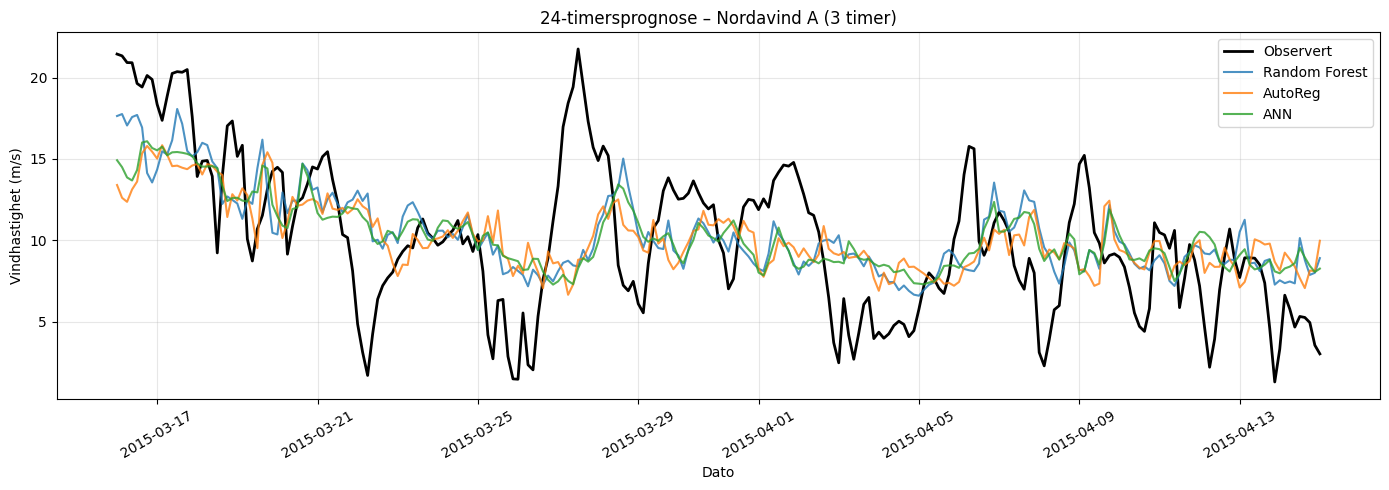

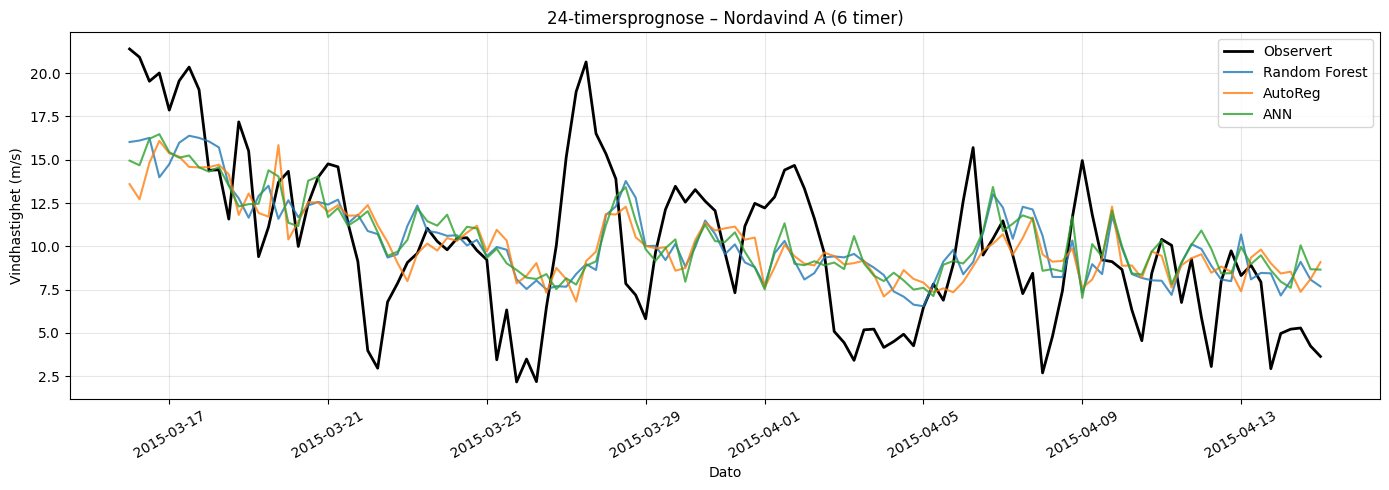

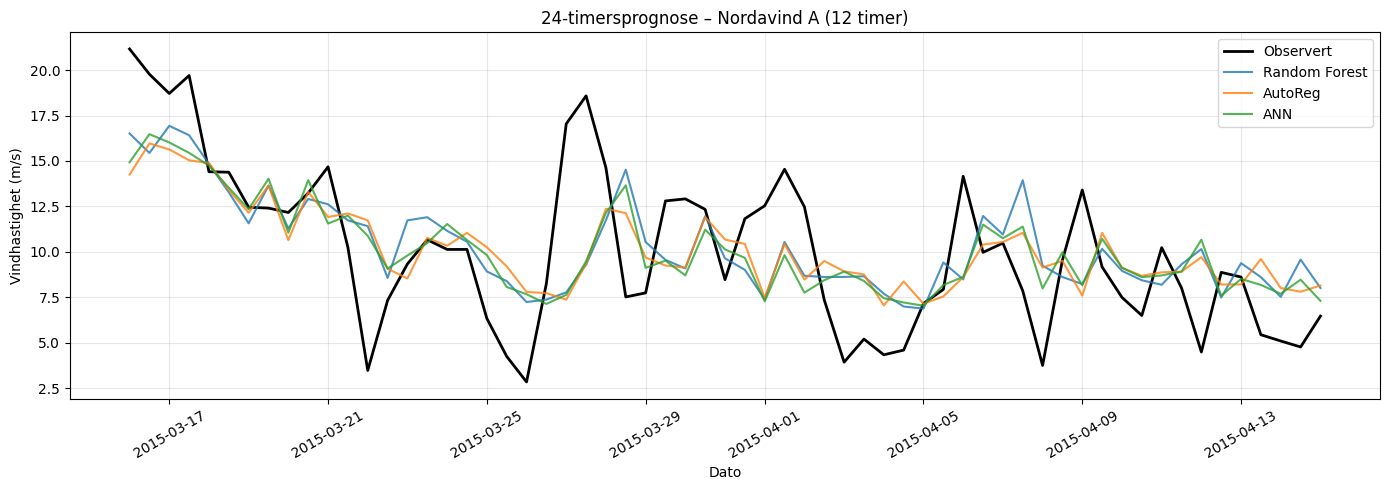

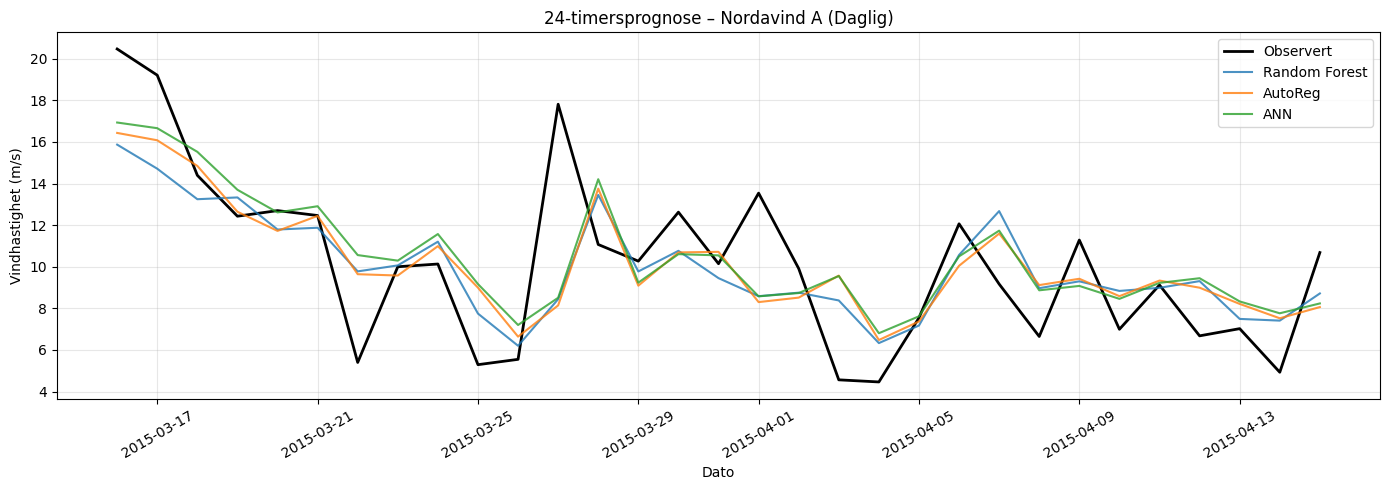

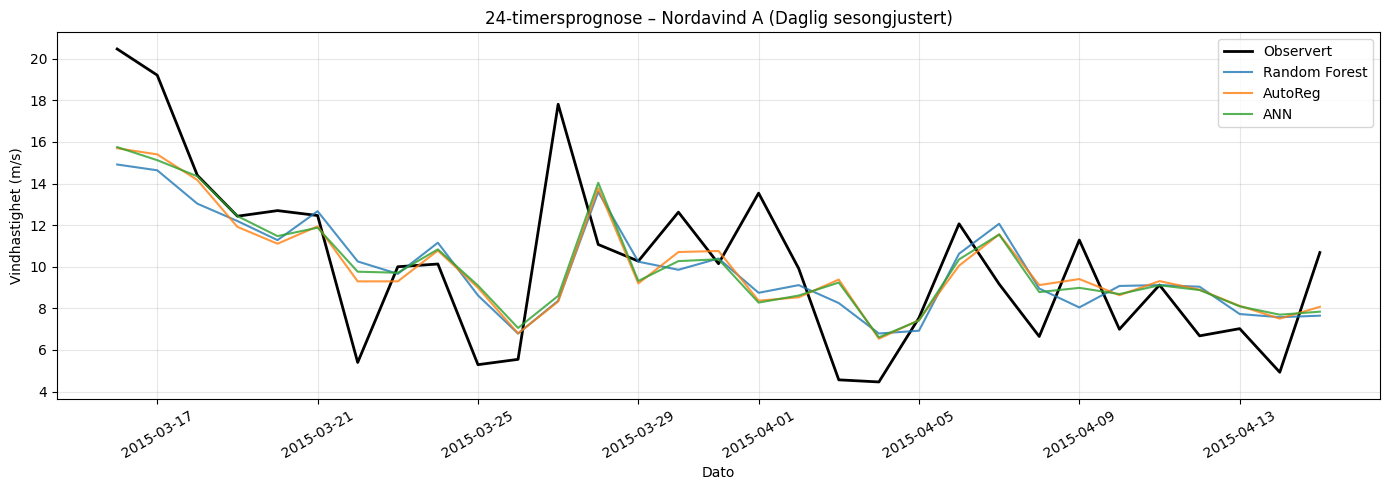

In [18]:
for resolution, df_plot in predictions_all.items():

    # Vis de første 30 dagene i testperioden
    start = df_plot["datetime"].min()
    end = start + pd.Timedelta(days=30)

    plot_data = df_plot.loc[
        (df_plot["datetime"] >= start) &
        (df_plot["datetime"] <= end)
    ]

    plt.figure(figsize=(14, 5))

    plt.plot(
        plot_data["datetime"],
        plot_data["Observert"],
        label="Observert",
        color="black",
        linewidth=2
    )

    for name in ["Random Forest", "AutoReg", "ANN"]:
        plt.plot(
            plot_data["datetime"],
            plot_data[name],
            label=name,
            alpha=0.8
        )

    plt.title(
        f"24-timersprognose – Nordavind A ({resolution})"
    )
    plt.xlabel("Dato")
    plt.ylabel("Vindhastighet (m/s)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


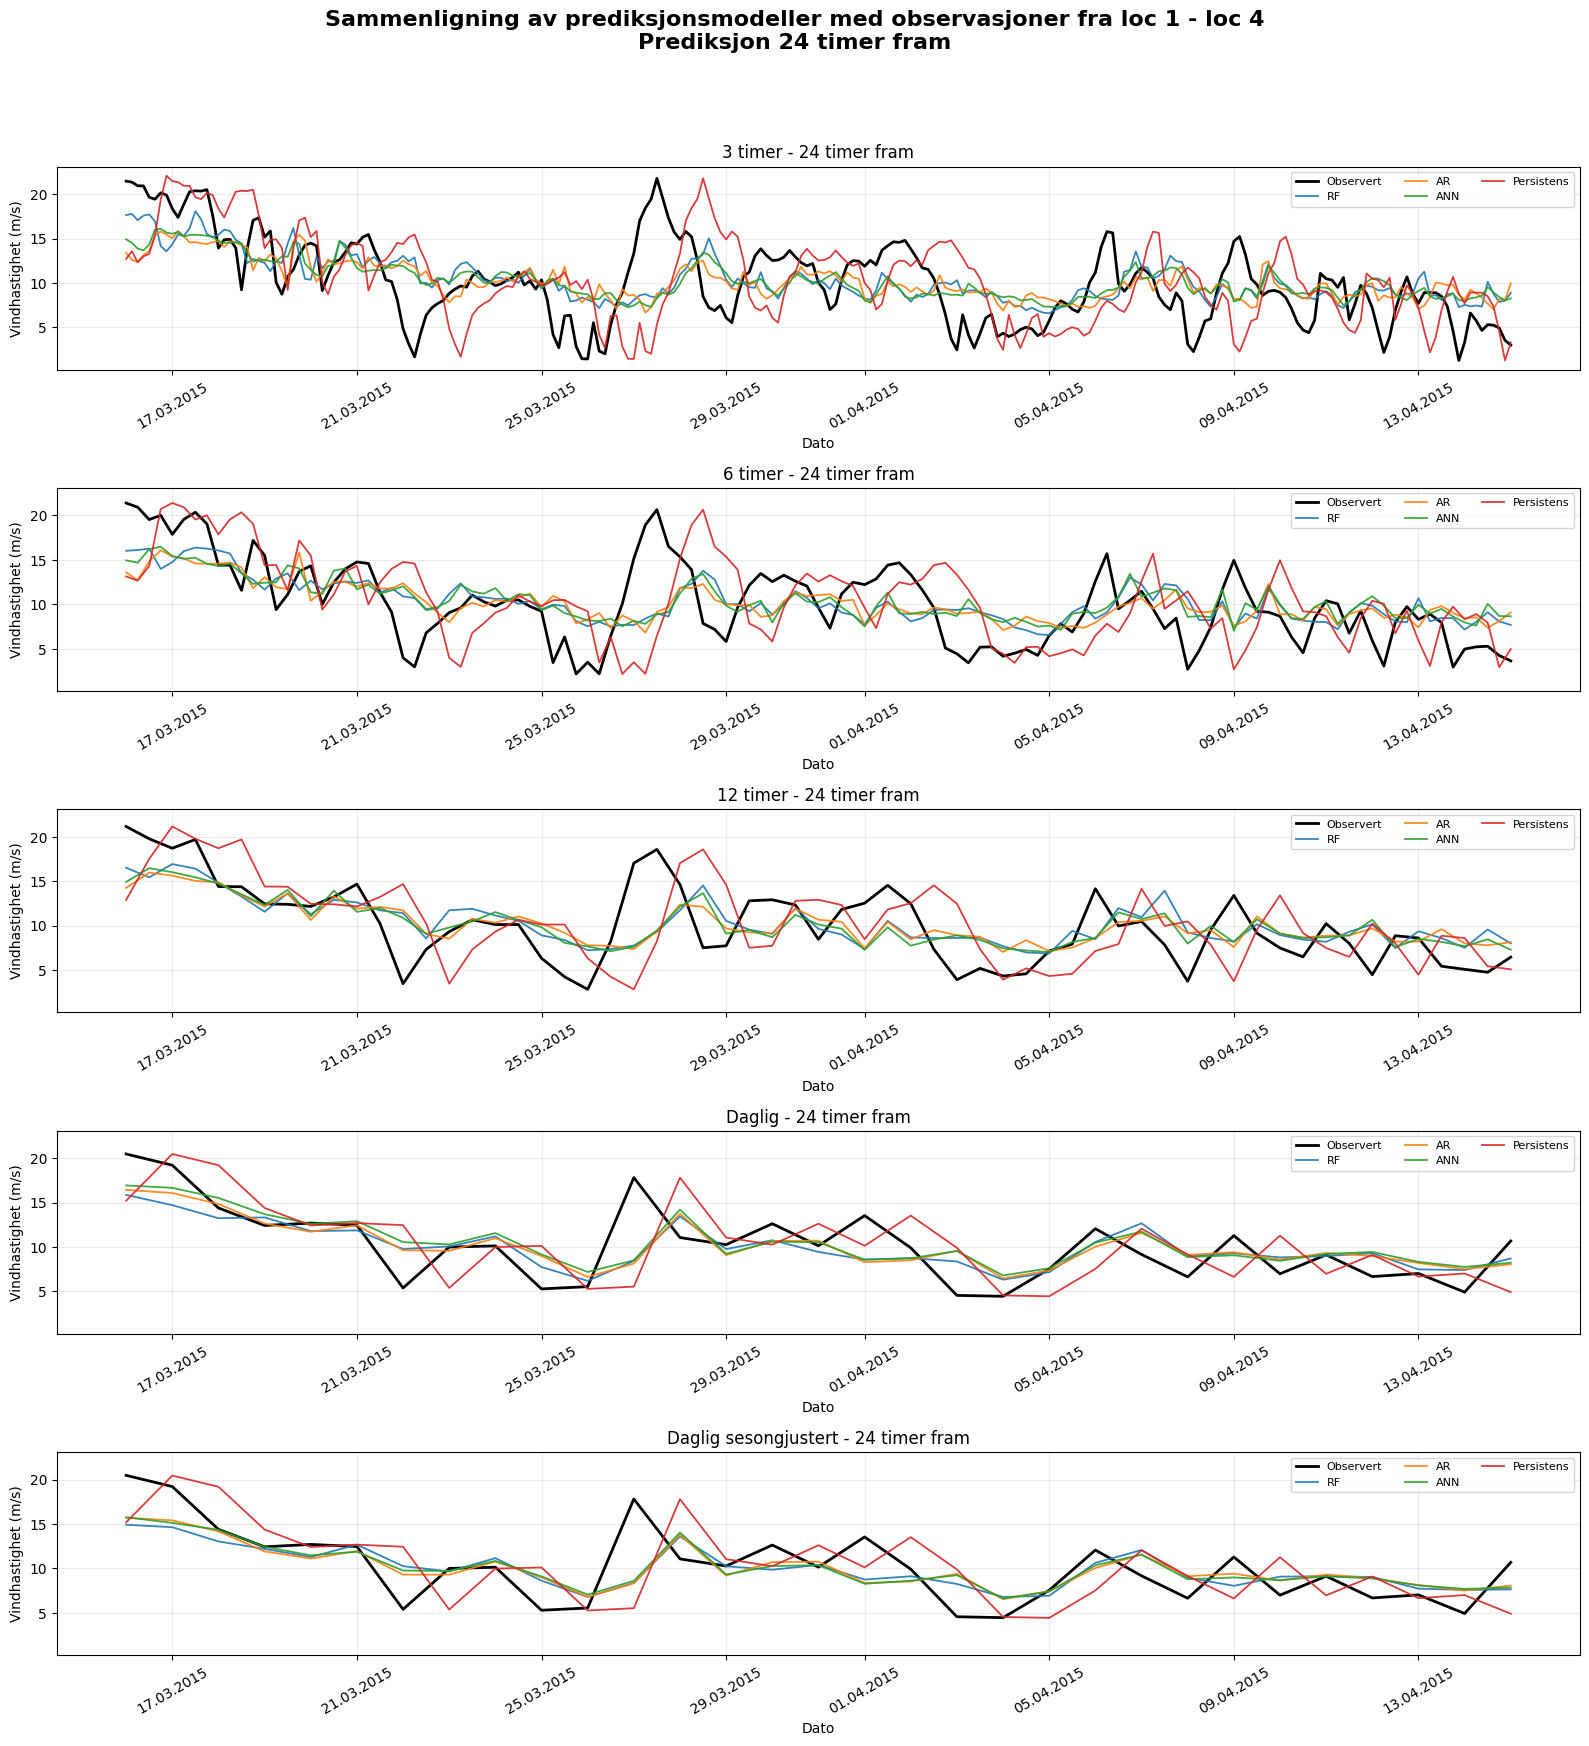

In [19]:
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.dates as mdates

# Modellnavn og farger
models = {
    "Observert": "black",
    "Random Forest": "tab:blue",
    "AutoReg": "tab:orange",
    "ANN": "tab:green",
    "Persistens": "tab:red",
    "Ukesgjennomsnitt": "tab:purple"
}

# Kortere navn i tegnforklaringen
labels = {
    "Observert": "Observert",
    "Random Forest": "RF",
    "AutoReg": "AR",
    "ANN": "ANN",
    "Persistens": "Persistens",
    "Ukesgjennomsnitt": "Ukesgjennomsnitt"
}

n_plots = len(predictions_all)

fig, axes = plt.subplots(
    n_plots, 1,
    figsize=(16, 3.5 * n_plots),
    sharey=True
)

if n_plots == 1:
    axes = [axes]

for ax, (resolution, df_plot) in zip(
    axes, predictions_all.items()
):

    # Første 30 dager i testperioden
    start = df_plot["datetime"].min()
    end = start + pd.Timedelta(days=30)

    plot_data = df_plot.loc[
        (df_plot["datetime"] >= start) &
        (df_plot["datetime"] <= end)
    ].sort_values("datetime")

    # Plott alle modellene
    for name, color in models.items():

        if name not in plot_data.columns:
            continue

        ax.plot(
            plot_data["datetime"],
            plot_data[name],
            label=labels[name],
            color=color,
            linewidth=2 if name == "Observert" else 1.3,
            alpha=1 if name == "Observert" else 0.9
        )

    ax.set_title(
        f"{resolution} - 24 timer fram",
        fontsize=12
    )

    ax.set_ylabel("Vindhastighet (m/s)")
    ax.set_xlabel("Dato")

    ax.grid(alpha=0.25)

    # Datoformat
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%d.%m.%Y")
    )

    ax.xaxis.set_major_locator(
        mdates.AutoDateLocator()
    )

    ax.tick_params(axis="x", rotation=30)

    # Tegnforklaring i hvert delplott
    ax.legend(
        loc="upper right",
        ncol=3,
        fontsize=8,
        frameon=True
    )

fig.suptitle(
    "Sammenligning av prediksjonsmodeller med observasjoner fra loc 1 - loc 4\n"
    "Prediksjon 24 timer fram",
    fontsize=16,
    fontweight="bold",
    y=0.995
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    "Sammenligning_24timer_Nordavind_A.pdf",
    bbox_inches="tight",
    dpi=300
)

plt.show()

Modell,ANN,AutoReg,Historisk gjennomsnitt,Persistens,Random Forest
Tidsoppløsning,,,,,
3 timer,4.1505,4.2406,4.6233,5.4585,4.1291
6 timer,4.0208,4.1021,4.5209,5.2894,4.0157
12 timer,3.7700,3.8188,4.2967,4.8993,3.7784
Daglig,3.1959,3.1759,3.7914,3.9129,3.1970
Daglig sesongjustert,3.1708,3.1650,3.7905,3.9129,3.2135


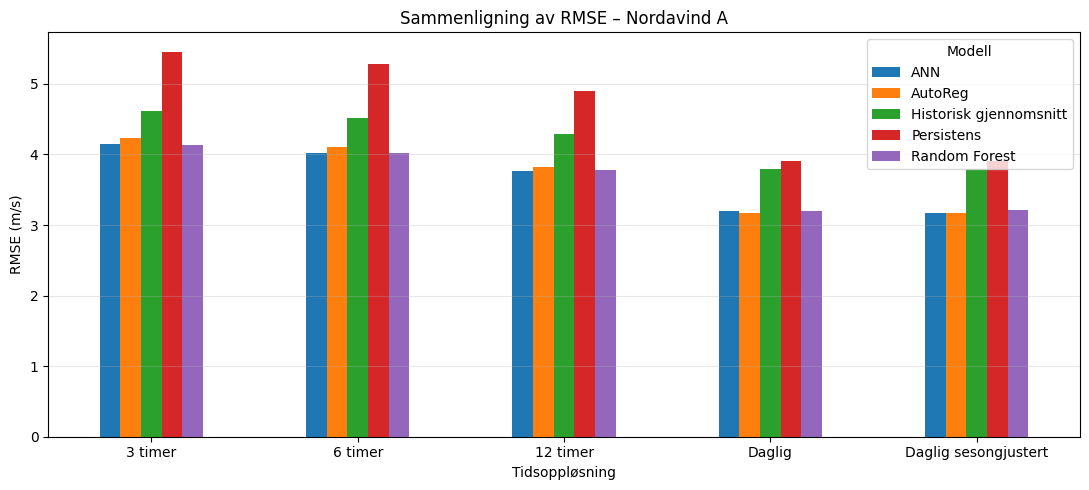


Beste modell:


,Modell,Tidsoppløsning,MSE,RMSE,MAE,R²
20,AutoReg,Daglig sesongjustert,10.017111,3.164982,2.549994,0.257034


In [20]:
rmse_table = results_df.pivot(
    index="Tidsoppløsning",
    columns="Modell",
    values="RMSE"
)

display(rmse_table.round(4))

ax = rmse_table.plot(
    kind="bar",
    figsize=(11, 5),
    rot=0
)

ax.set_title("Sammenligning av RMSE – Nordavind A")
ax.set_ylabel("RMSE (m/s)")
ax.set_xlabel("Tidsoppløsning")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nBeste modell:")
display(
    results_df.sort_values("RMSE").head(1)
)

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Gamle resultater
results_old = pd.read_csv("samlet_modellsammenligning.csv")

# Nye resultater
results_new = results_df.copy()

# Legg til hvilken kjøring resultatene kommer fra
results_old["Resultat"] = "Gammel"
results_new["Resultat"] = "Ny"

# Kombiner resultatene
results_comparison = pd.concat(
    [results_old, results_new],
    ignore_index=True
)

display(results_comparison)

,Modell,Tidsoppløsning,MSE,RMSE,MAE,R²,Resultat
0,ANN,3 timer,18.235717,4.270330,3.468628,0.058726,Gammel
1,AutoReg,3 timer,18.316880,4.279822,3.462388,0.056813,Gammel
2,Historisk gjennomsnitt,3 timer,21.393334,4.625293,3.729365,-0.104261,Gammel
3,Persistens,3 timer,29.696228,5.449425,4.304176,-0.532832,Gammel
4,Random Forest,3 timer,18.117221,4.256433,3.436519,0.064842,Gammel
5,ANN,6 timer,17.349346,4.165255,3.378163,0.060599,Gammel
6,AutoReg,6 timer,17.405005,4.171931,3.378610,0.063152,Gammel
7,Historisk gjennomsnitt,6 timer,20.460507,4.523329,3.646120,-0.104469,Gammel
8,Persistens,6 timer,27.886720,5.280788,4.177006,-0.505340,Gammel
9,Random Forest,6 timer,17.300670,4.159407,3.363855,0.066101,Gammel


In [22]:
rmse_comparison = results_comparison.pivot_table(
    index=["Tidsoppløsning", "Modell"],
    columns="Resultat",
    values="RMSE",
    aggfunc="first"
)

# Endring i RMSE
rmse_comparison["Endring"] = (
    rmse_comparison["Ny"] - rmse_comparison["Gammel"]
)

# Prosentvis endring
rmse_comparison["Endring (%)"] = (
    rmse_comparison["Endring"]
    / rmse_comparison["Gammel"] * 100
)

display(rmse_comparison.round(4))

Resultat                                     Gammel      Ny  Endring  \
Tidsoppløsning       Modell                                            
12 timer             ANN                     3.9186  3.7700  -0.1487   
                     AutoReg                 3.9300  3.8188  -0.1112   
                     Historisk gjennomsnitt  4.3000  4.2967  -0.0033   
                     Persistens              4.8913  4.8993   0.0080   
                     Random Forest           3.9462  3.7784  -0.1678   
3 timer              ANN                     4.2703  4.1505  -0.1198   
                     AutoReg                 4.2798  4.2406  -0.0392   
                     Historisk gjennomsnitt  4.6253  4.6233  -0.0019   
                     Persistens              5.4494  5.4585   0.0091   
                     Random Forest           4.2564  4.1291  -0.1273   
6 timer              ANN                     4.1653  4.0208  -0.1444   
                     AutoReg                 4.1719  4.1021  -0.0699   
                     Historisk gjennomsnitt  4.5233  4.5209  -0.0024   
                     Persistens              5.2808  5.2894   0.0086   
                     Random Forest           4.1594  4.0157  -0.1437   
Daglig               ANN                     3.3073  3.1959  -0.1115   
                     AutoReg                 3.3156  3.1759  -0.1397   
                     Historisk gjennomsnitt  3.7964  3.7914  -0.0049   
                     Persistens              3.9088  3.9129   0.0041   
                     Random Forest           3.3928  3.1970  -0.1959   
Daglig sesongjustert ANN                     3.2964  3.1708  -0.1255   
                     AutoReg                 3.2919  3.1650  -0.1269   
                     Historisk gjennomsnitt  3.7957  3.7905  -0.0052   
                     Persistens              3.9088  3.9129   0.0041   
                     Random Forest           3.3803  3.2135  -0.1668   

Resultat                                     Endring (%)  
Tidsoppløsning       Modell                               
12 timer             ANN                         -3.7939  
                     AutoReg                     -2.8291  
                     Historisk gjennomsnitt      -0.0769  
                     Persistens                   0.1637  
                     Random Forest               -4.2529  
3 timer              ANN                         -2.8060  
                     AutoReg                     -0.9163  
                     Historisk gjennomsnitt      -0.0420  
                     Persistens                   0.1666  
                     Random Forest               -2.9905  
6 timer              ANN                         -3.4674  
                     AutoReg                     -1.6745  
                     Historisk gjennomsnitt      -0.0526  
                     Persistens                   0.1638  
                     Random Forest               -3.4551  
Daglig               ANN                         -3.3706  
                     AutoReg                     -4.2123  
                     Historisk gjennomsnitt      -0.1302  
                     Persistens                   0.1053  
                     Random Forest               -5.7733  
Daglig sesongjustert ANN                         -3.8086  
                     AutoReg                     -3.8551  
                     Historisk gjennomsnitt      -0.1365  
                     Persistens                   0.1054  
                     Random Forest               -4.9339

In [23]:

coefficients = seasonal_coefficients[
    "Daglig sesongjustert"
]

season_table = pd.DataFrame(
    coefficients,
    index=["mu0", "mu1", "mu2"]
).T

season_table["Amplitude"] = np.sqrt(
    season_table["mu1"]**2 +
    season_table["mu2"]**2
)

display(season_table.round(4))

,mu0,mu1,mu2,Amplitude
Nordavind_A,9.4627,1.4697,0.1667,1.4791
Nordavind_B,9.5995,1.4798,0.2406,1.4993
Nordavind_C,9.5555,1.6323,0.3202,1.6634
Nordavind_D,9.5434,1.6694,0.2923,1.6948


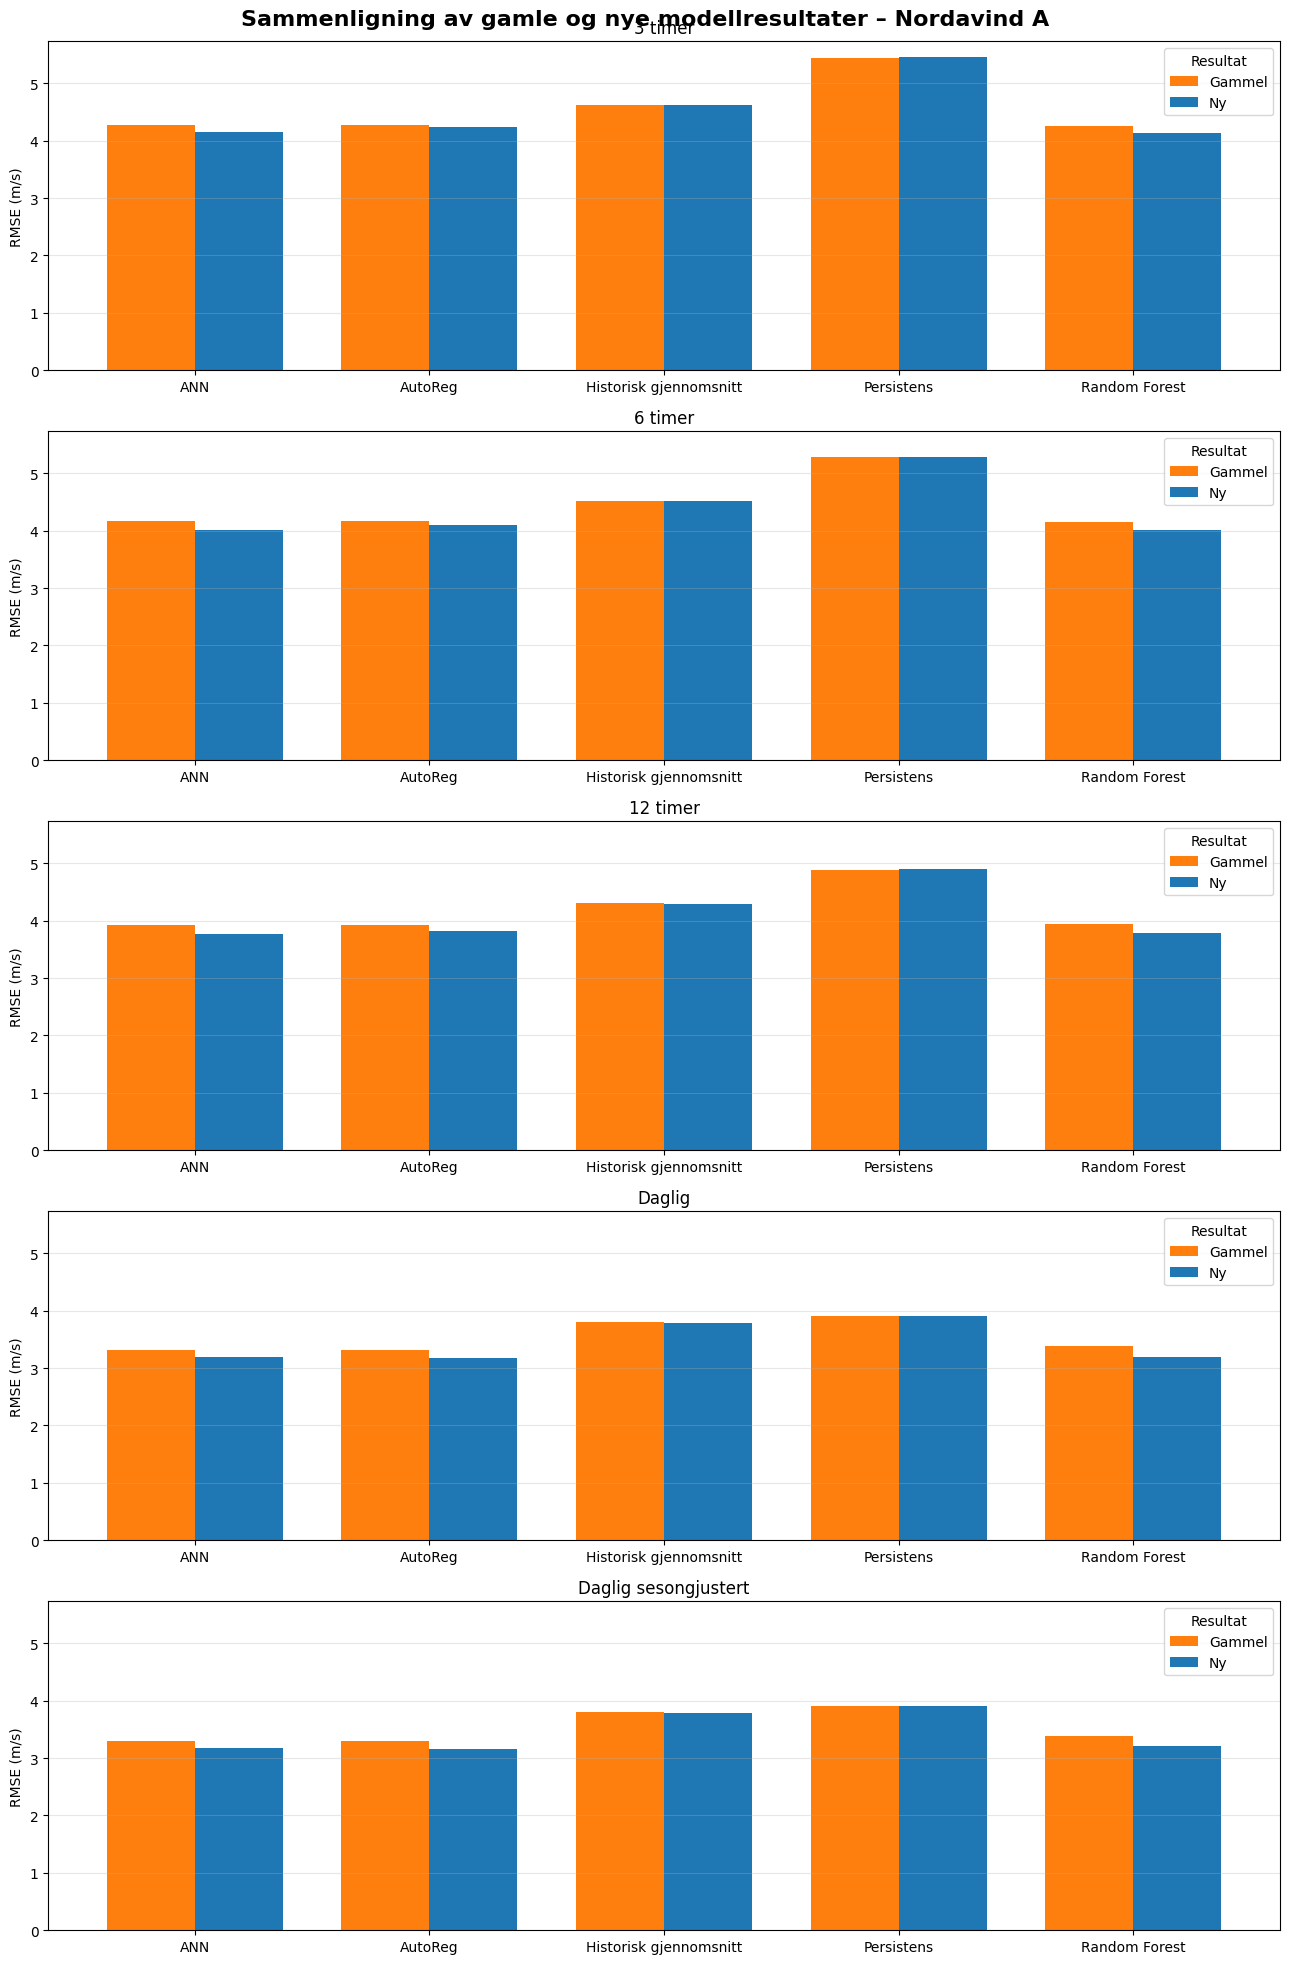

In [24]:
# Ønsket rekkefølge
resolution_order = [
    "3 timer",
    "6 timer",
    "12 timer",
    "Daglig",
    "Daglig sesongjustert"
]

# Velg tidsoppløsninger som finnes
resolutions = [
    r for r in resolution_order
    if r in results_comparison["Tidsoppløsning"].values
]

fig, axes = plt.subplots(
    len(resolutions), 1,
    figsize=(13, 4 * len(resolutions)),
    sharey=True
)

axes = np.atleast_1d(axes)

for ax, resolution in zip(axes, resolutions):

    subset = results_comparison[
        results_comparison["Tidsoppløsning"] == resolution
    ]

    table = subset.pivot_table(
        index="Modell",
        columns="Resultat",
        values="RMSE",
        aggfunc="first"
    )

    # Sammenlign gamle og nye resultater
    table = table.reindex(columns=["Gammel", "Ny"])

    table.plot(
        kind="bar",
        ax=ax,
        color=["tab:orange", "tab:blue"],
        width=0.75,
        rot=0
    )

    ax.set_title(resolution)
    ax.set_ylabel("RMSE (m/s)")
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Resultat")

fig.suptitle(
    "Sammenligning av gamle og nye modellresultater – Nordavind A",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

In [25]:
r2_comparison = results_comparison.pivot_table(
    index=["Tidsoppløsning", "Modell"],
    columns="Resultat",
    values="R²",
    aggfunc="first"
)

# Endring i R²
r2_comparison["Endring"] = (
    r2_comparison["Ny"] - r2_comparison["Gammel"]
)

# Vurdering
r2_comparison["Vurdering"] = np.where(
    r2_comparison["Endring"] > 0,
    "Forbedret",
    np.where(
        r2_comparison["Endring"] < 0,
        "Forverret",
        "Uendret"
    )
)

display(r2_comparison.round(4))

Resultat                                     Gammel      Ny  Endring  \
Tidsoppløsning       Modell                                            
12 timer             ANN                     0.0808  0.1550   0.0742   
                     AutoReg                 0.0820  0.1330   0.0510   
                     Historisk gjennomsnitt -0.1024 -0.0976   0.0049   
                     Persistens             -0.4265 -0.4270  -0.0006   
                     Random Forest           0.0715  0.1513   0.0797   
3 timer              ANN                     0.0587  0.1136   0.0549   
                     AutoReg                 0.0568  0.0747   0.0179   
                     Historisk gjennomsnitt -0.1043 -0.0999   0.0044   
                     Persistens             -0.5328 -0.5332  -0.0003   
                     Random Forest           0.0648  0.1227   0.0578   
6 timer              ANN                     0.0606  0.1299   0.0693   
                     AutoReg                 0.0632  0.0944   0.0313   
                     Historisk gjennomsnitt -0.1045 -0.1000   0.0045   
                     Persistens             -0.5053 -0.5057  -0.0004   
                     Random Forest           0.0661  0.1322   0.0661   
Daglig               ANN                     0.1847  0.2425   0.0578   
                     AutoReg                 0.1857  0.2519   0.0662   
                     Historisk gjennomsnitt -0.0687 -0.0662   0.0025   
                     Persistens             -0.1329 -0.1356  -0.0027   
                     Random Forest           0.1464  0.2419   0.0955   
Daglig sesongjustert ANN                     0.1943  0.2543   0.0600   
                     AutoReg                 0.1973  0.2570   0.0597   
                     Historisk gjennomsnitt -0.0683 -0.0657   0.0026   
                     Persistens             -0.1329 -0.1356  -0.0027   
                     Random Forest           0.1528  0.2341   0.0813   

Resultat                                     Vurdering  
Tidsoppløsning       Modell                             
12 timer             ANN                     Forbedret  
                     AutoReg                 Forbedret  
                     Historisk gjennomsnitt  Forbedret  
                     Persistens              Forverret  
                     Random Forest           Forbedret  
3 timer              ANN                     Forbedret  
                     AutoReg                 Forbedret  
                     Historisk gjennomsnitt  Forbedret  
                     Persistens              Forverret  
                     Random Forest           Forbedret  
6 timer              ANN                     Forbedret  
                     AutoReg                 Forbedret  
                     Historisk gjennomsnitt  Forbedret  
                     Persistens              Forverret  
                     Random Forest           Forbedret  
Daglig               ANN                     Forbedret  
                     AutoReg                 Forbedret  
                     Historisk gjennomsnitt  Forbedret  
                     Persistens              Forverret  
                     Random Forest           Forbedret  
Daglig sesongjustert ANN                     Forbedret  
                     AutoReg                 Forbedret  
                     Historisk gjennomsnitt  Forbedret  
                     Persistens              Forverret  
                     Random Forest           Forbedret

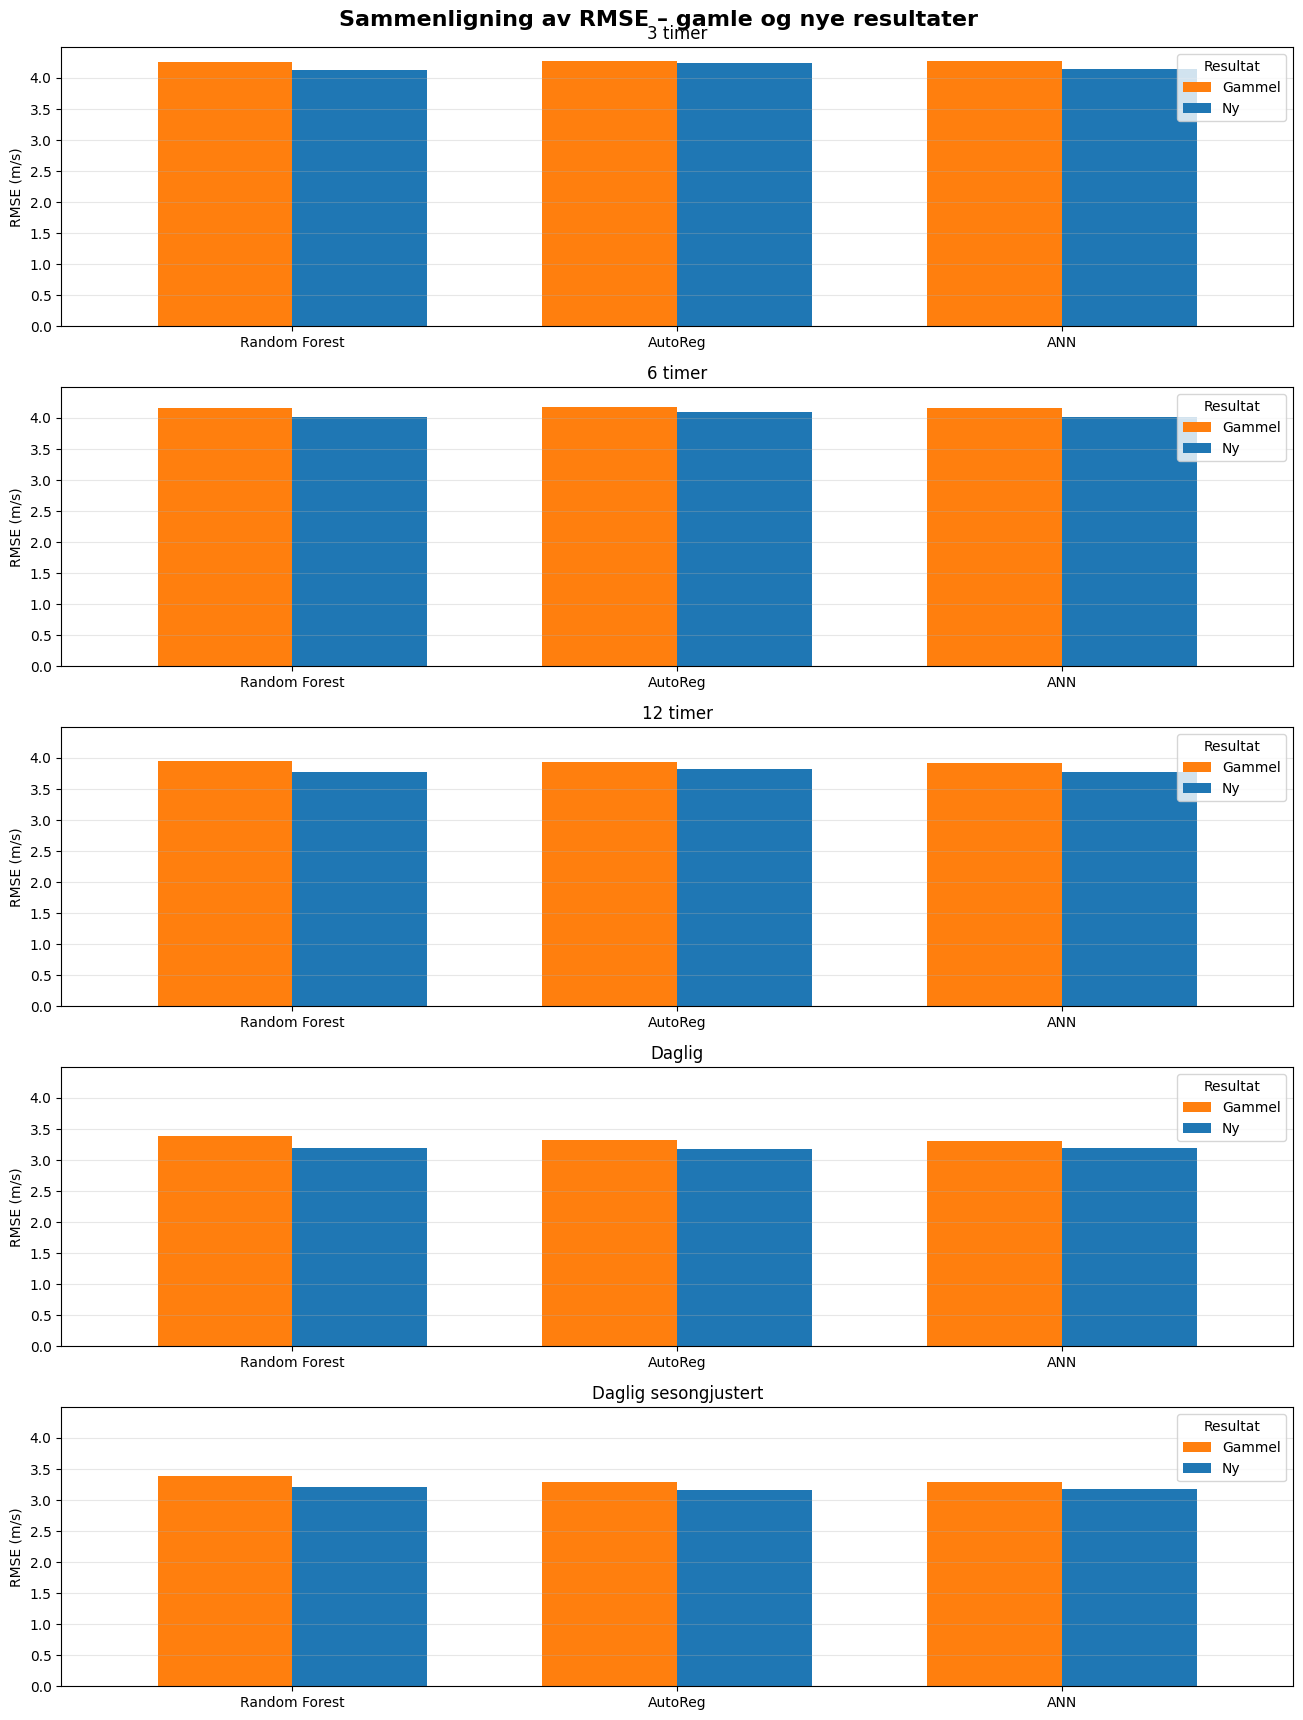

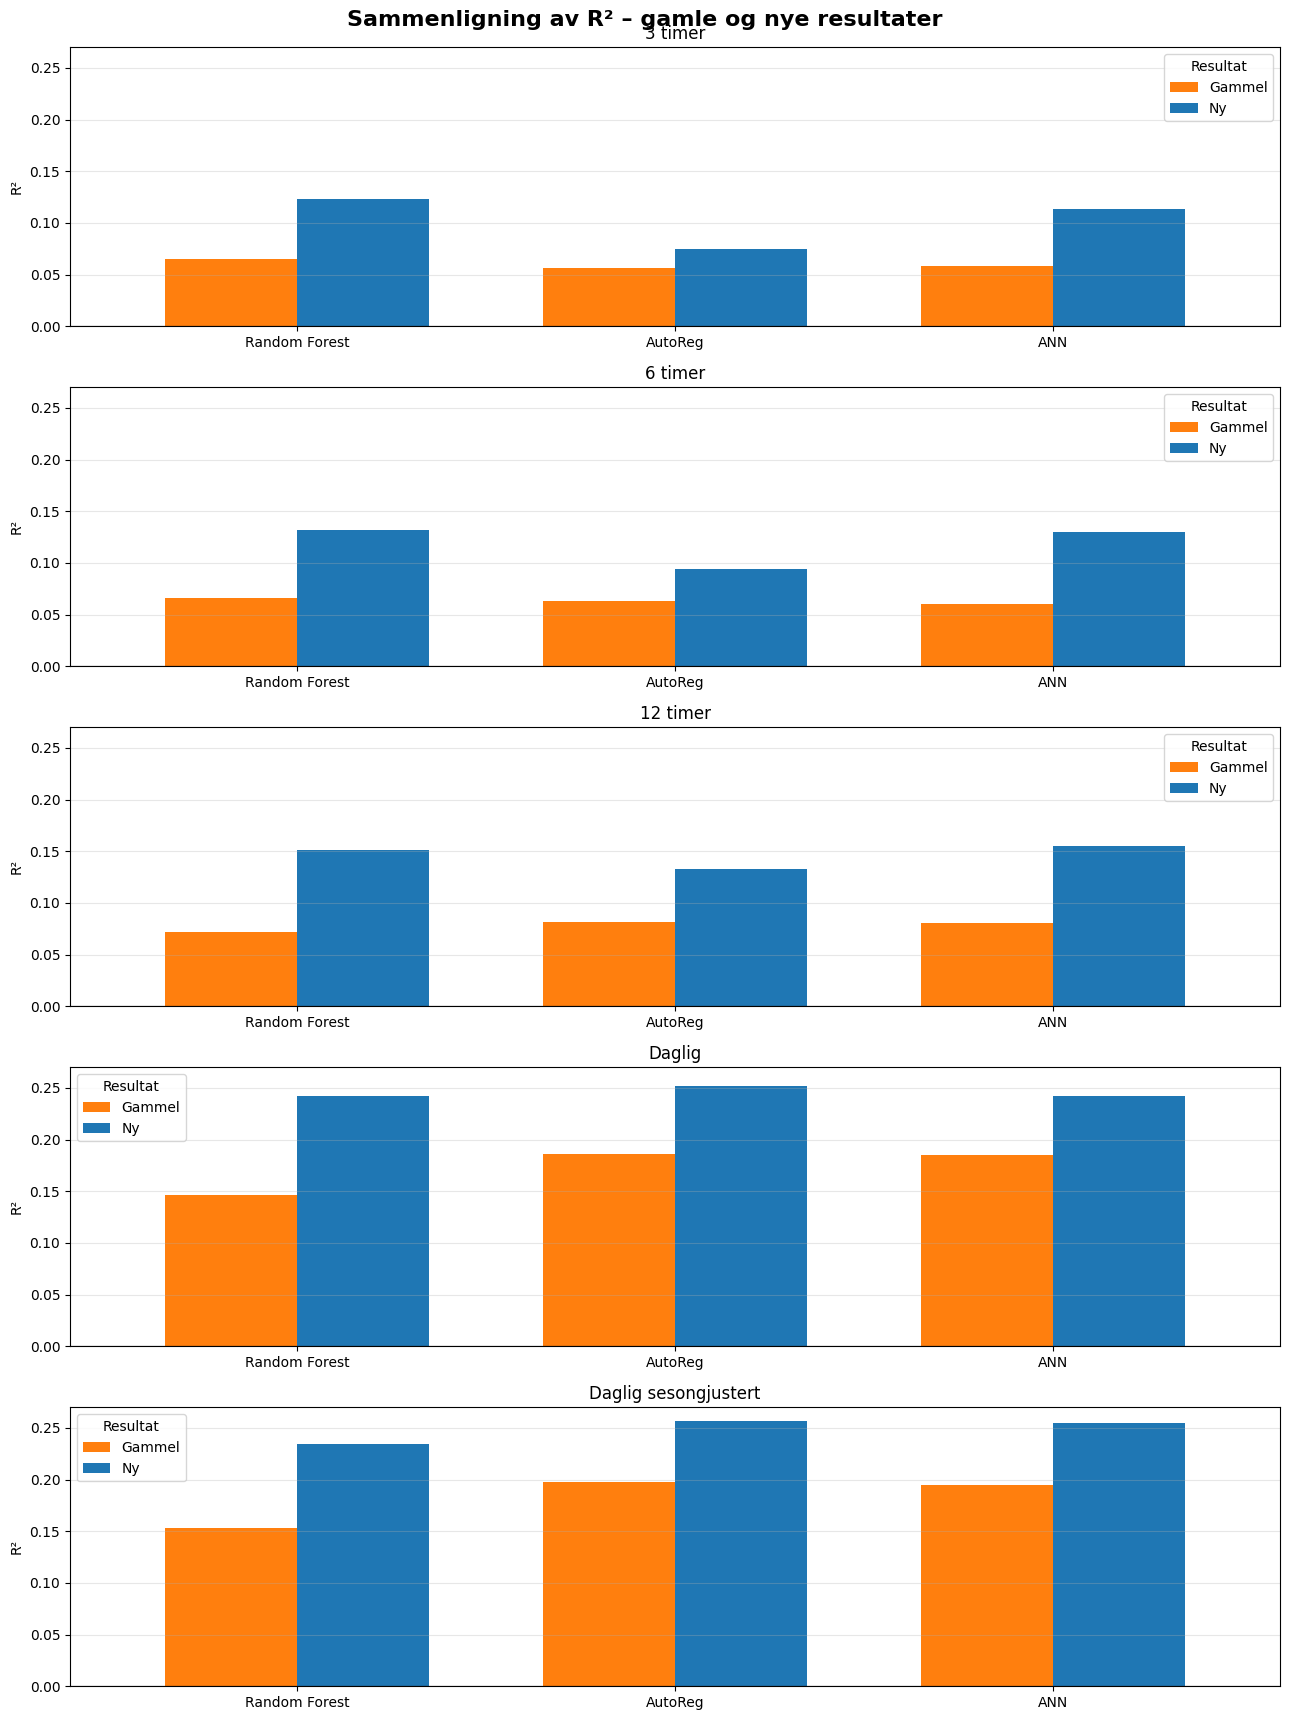

In [26]:
import matplotlib.pyplot as plt
import numpy as np

# Kun prediksjonsmodellene
models = ["Random Forest", "AutoReg", "ANN"]

# Fjern benchmarkmodellene
results_filtered = results_comparison[
    results_comparison["Modell"].isin(models)
].copy()

resolution_order = [
    "3 timer",
    "6 timer",
    "12 timer",
    "Daglig",
    "Daglig sesongjustert"
]

resolutions = [
    r for r in resolution_order
    if r in results_filtered["Tidsoppløsning"].values
]

# Lag figurer for både RMSE og R²
for metric in ["RMSE", "R²"]:

    fig, axes = plt.subplots(
        len(resolutions), 1,
        figsize=(13, 3.5 * len(resolutions)),
        sharey=True
    )

    axes = np.atleast_1d(axes)

    for ax, resolution in zip(axes, resolutions):

        subset = results_filtered[
            results_filtered["Tidsoppløsning"] == resolution
        ]

        table = subset.pivot_table(
            index="Modell",
            columns="Resultat",
            values=metric,
            aggfunc="first"
        )

        table = table.reindex(
            index=models,
            columns=["Gammel", "Ny"]
        )

        table.plot(
            kind="bar",
            ax=ax,
            color=["tab:orange", "tab:blue"],
            width=0.7,
            rot=0
        )

        ax.set_title(resolution)
        ax.set_ylabel(
            "RMSE (m/s)" if metric == "RMSE" else "R²"
        )
        ax.set_xlabel("")
        ax.grid(axis="y", alpha=0.3)
        ax.legend(title="Resultat")

        if metric == "R²":
            ax.axhline(0, color="black", linewidth=0.8)

    fig.suptitle(
        f"Sammenligning av {metric} – gamle og nye resultater",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

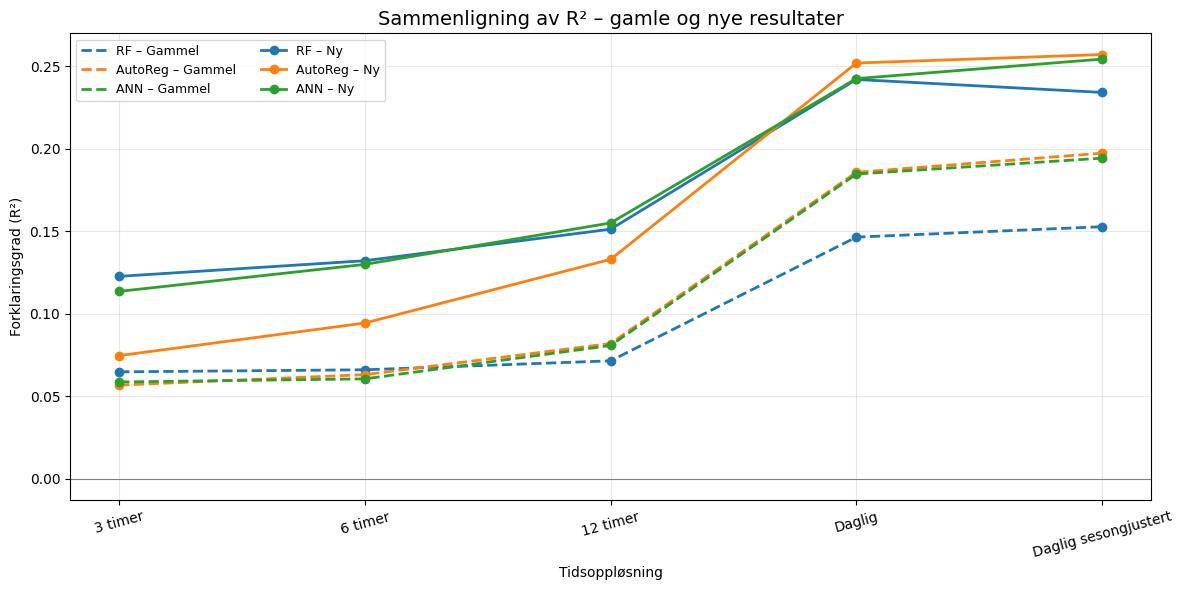

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

models = ["Random Forest", "AutoReg", "ANN"]

resolution_order = [
    "3 timer",
    "6 timer",
    "12 timer",
    "Daglig",
    "Daglig sesongjustert"
]

farger = {
    "Random Forest": "tab:blue",
    "AutoReg": "tab:orange",
    "ANN": "tab:green"
}

# ==========================================
# 1. Klargjør data
# ==========================================

results_filtered = results_comparison[
    results_comparison["Modell"].isin(models)
].copy()

df_r2 = results_filtered.pivot_table(
    index="Tidsoppløsning",
    columns=["Modell", "Resultat"],
    values="R²",
    aggfunc="first"
)

df_r2 = df_r2.reindex(resolution_order)

# ==========================================
# 2. Lag linjediagram
# ==========================================

fig, ax = plt.subplots(figsize=(12, 6))

for modell in models:

    for resultat in ["Gammel", "Ny"]:

        kolonne = (modell, resultat)

        if kolonne not in df_r2.columns:
            continue

        ax.plot(
            df_r2.index,
            df_r2[kolonne],
            marker="o",
            linestyle="--" if resultat == "Gammel" else "-",
            linewidth=2,
            markersize=6,
            color=farger[modell]
        )

# ==========================================
# 3. Egendefinert legend med to kolonner
# ==========================================

handles = []
labels = []

# Gamle modeller først
for modell in models:

    navn = "RF" if modell == "Random Forest" else modell

    handles.append(
        Line2D(
            [0], [0],
            color=farger[modell],
            linestyle="--",
            marker=None,
            linewidth=2
        )
    )

    labels.append(f"{navn} – Gammel")

# Nye modeller etterpå
for modell in models:

    navn = "RF" if modell == "Random Forest" else modell

    handles.append(
        Line2D(
            [0], [0],
            color=farger[modell],
            linestyle="-",
            marker="o",
            linewidth=2
        )
    )

    labels.append(f"{navn} – Ny")

ax.legend(
    handles,
    labels,
    ncol=2,
    loc="upper left",
    fontsize=9,
    columnspacing=2
)

# ==========================================
# 4. Formatering
# ==========================================

ax.set_xlabel("Tidsoppløsning")
ax.set_ylabel("Forklaringsgrad (R²)")

ax.set_title(
    "Sammenligning av R² – gamle og nye resultater",
    fontsize=14
)

ax.axhline(
    0,
    color="gray",
    linewidth=0.8
)

ax.grid(alpha=0.3)

plt.xticks(rotation=15)
plt.tight_layout()

# ==========================================
# 5. Lagre figur
# ==========================================

plt.savefig(
    "R2_gammel_ny.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "R2_gammel_ny.pdf",
    bbox_inches="tight"
)

plt.show()

In [28]:
print("Beste gamle modell:")
display(
    results_old.sort_values("RMSE").head(1)
)

print("Beste nye modell:")
display(
    results_new.sort_values("RMSE").head(1)
)

Beste gamle modell:


,Modell,Tidsoppløsning,MSE,RMSE,MAE,R²,Resultat
21,AutoReg,Daglig sesongjustert,10.836514,3.291886,2.660735,0.197297,Gammel


Beste nye modell:


,Modell,Tidsoppløsning,MSE,RMSE,MAE,R²,Resultat
20,AutoReg,Daglig sesongjustert,10.017111,3.164982,2.549994,0.257034,Ny


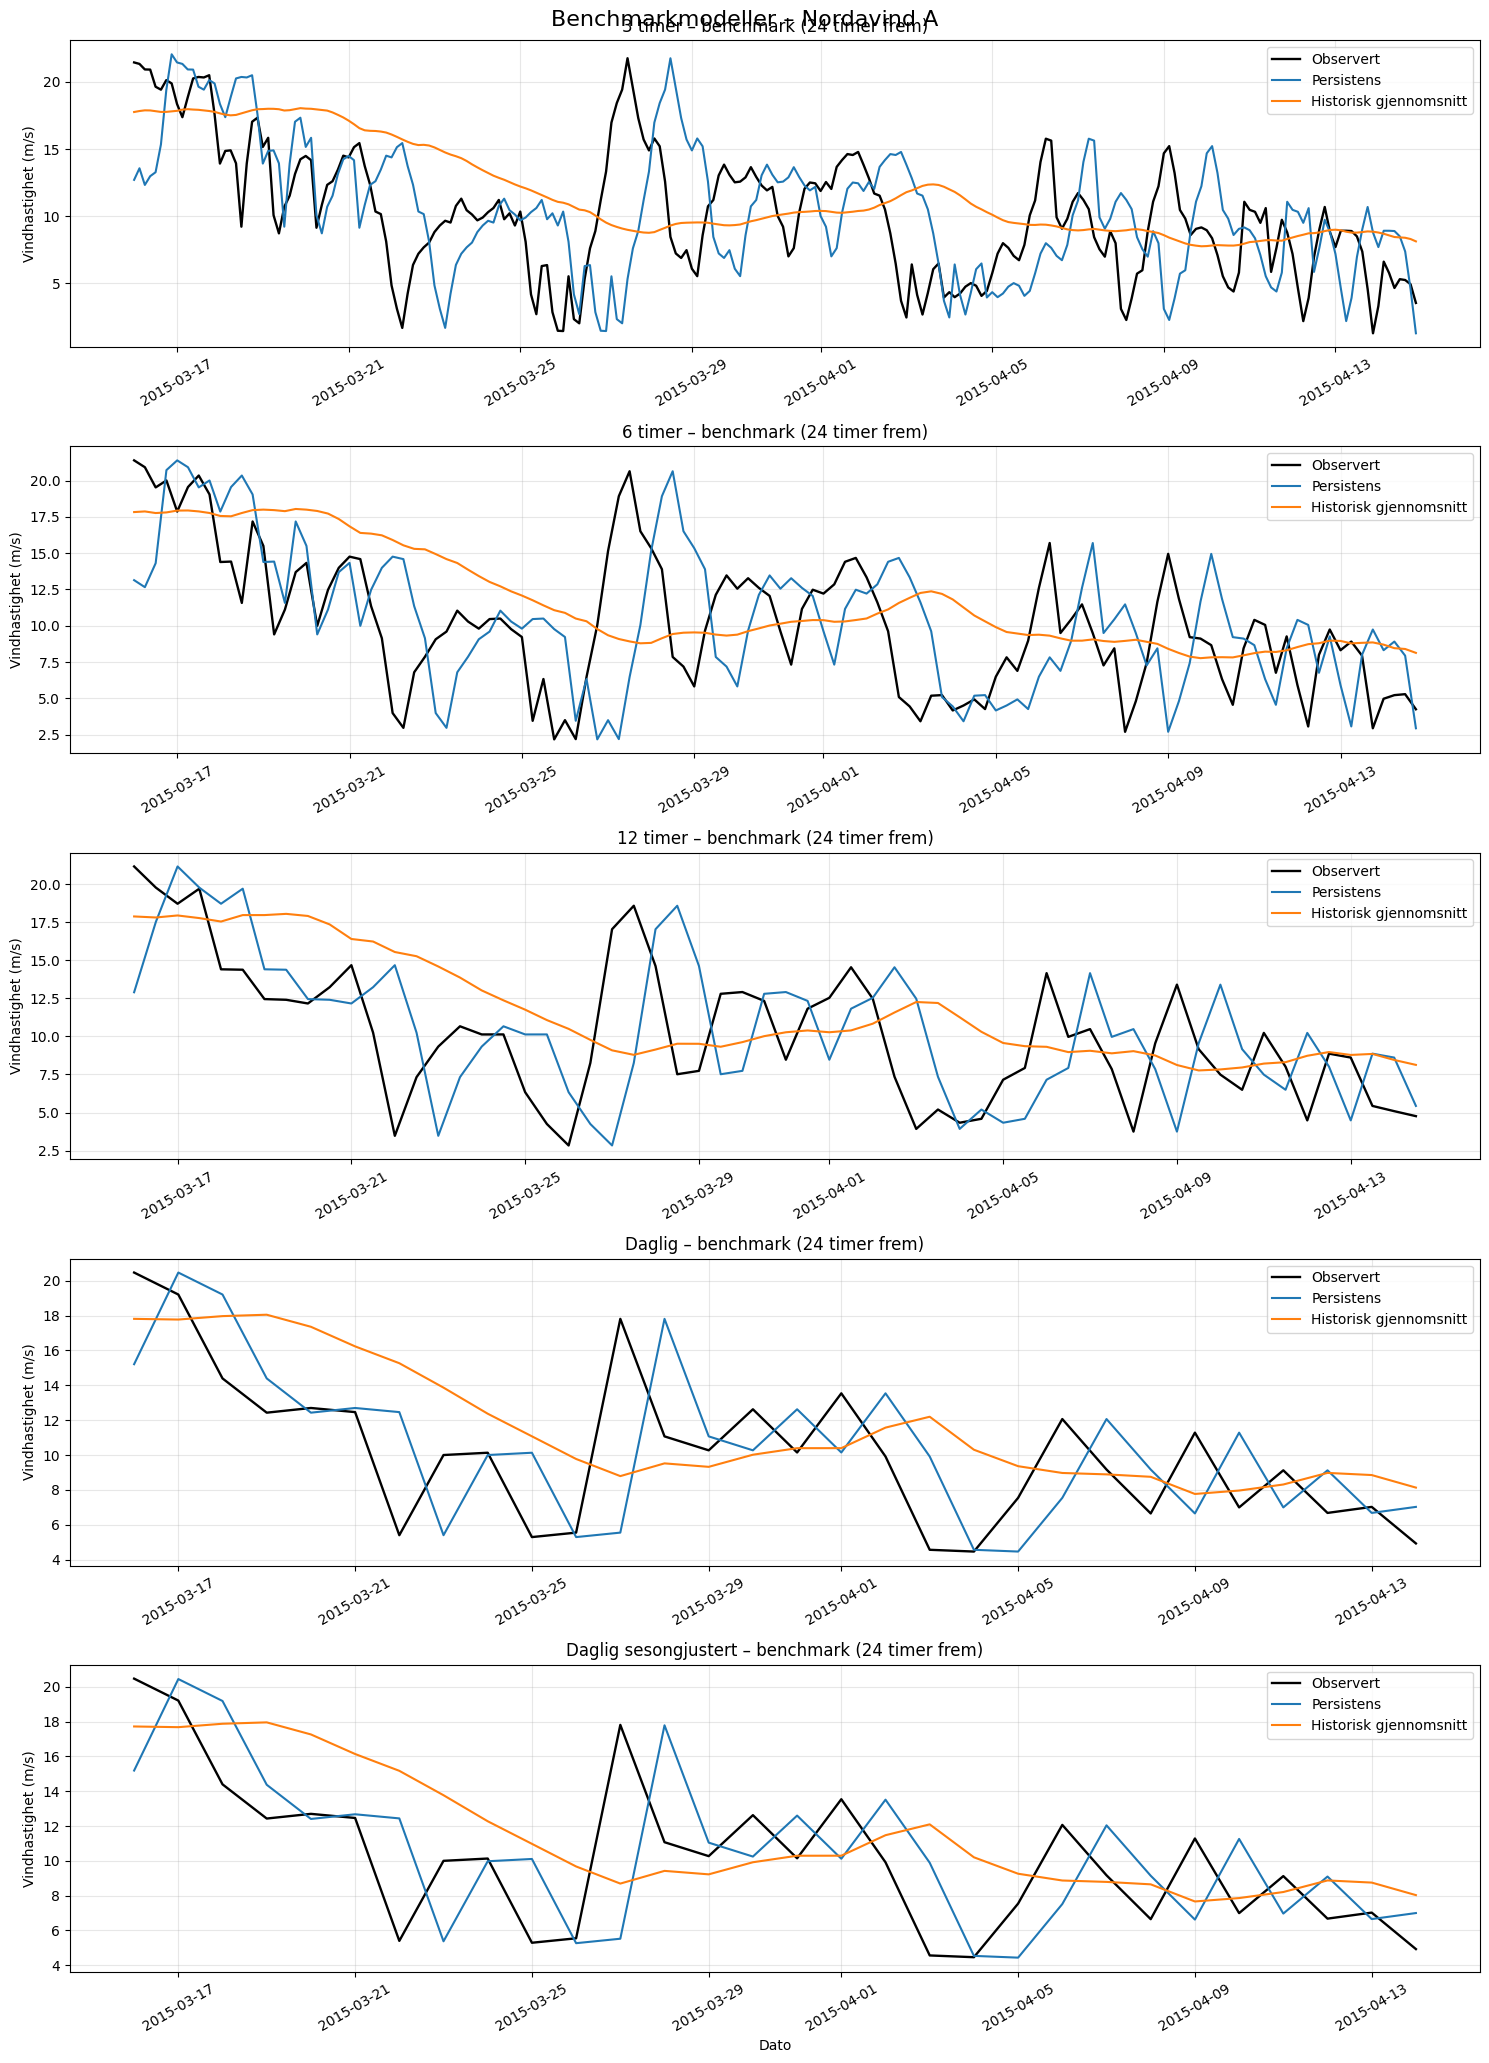

In [29]:

fig, axes = plt.subplots(
    5, 1,
    figsize=(15, 21)
)

for ax, (resolution, df_plot) in zip(
    axes,
    predictions_all.items()
):

    start = df_plot["datetime"].min()
    end = start + pd.Timedelta(days=30)

    plot_data = df_plot[
        (df_plot["datetime"] >= start) &
        (df_plot["datetime"] < end)
    ]

    ax.plot(
        plot_data["datetime"],
        plot_data["Observert"],
        color="black",
        linewidth=1.7,
        label="Observert"
    )

    ax.plot(
        plot_data["datetime"],
        plot_data["Persistens"],
        label="Persistens"
    )

    ax.plot(
        plot_data["datetime"],
        plot_data["Historisk gjennomsnitt"],
        label="Historisk gjennomsnitt"
    )

    ax.set_title(
        f"{resolution} – benchmark (24 timer frem)"
    )
    ax.set_ylabel("Vindhastighet (m/s)")
    ax.legend()
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=30)

axes[-1].set_xlabel("Dato")

plt.suptitle(
    "Benchmarkmodeller – Nordavind A",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "benchmark_nordavind_24h.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
